# Means with 95% Confidence Intervals

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

Plots each group's mean as a dot with a 95% confidence interval, over the raw observations. Readers see the estimate, its uncertainty, and the data behind it, which a bar-of-means ('dynamite plot') hides.

## When to use

- Compare group means from experiments or trials (dose groups, conditions)
- Show estimates together with their uncertainty
- Replace 'dynamite plots' (bars with error whiskers)

## Avoid when

- Distributions are strongly skewed or multimodal (show box, violin or raincloud plots)
- The audience may confuse SD, SE and CI (always say which one in the axis label or caption)

## Alternatives

- Box plot
- Raincloud plot
- Forest plot

## Design tips

- State whether the bars are SD, SE or 95% CI
- Draw the raw points lightly behind the summary, jittered horizontally

## Example

LDL cholesterol reduction after 12 weeks in four dose groups of a synthetic trial.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy import stats

### Data

In [2]:
rng = np.random.default_rng(6)
groups = ["Placebo", "10 mg", "20 mg", "40 mg"]
true_mean = [3, 18, 27, 33]
df = pd.concat([pd.DataFrame({"group": g, "ldl_reduction_pct": rng.normal(m, 11, rng.integers(22, 30))})
                for g, m in zip(groups, true_mean)], ignore_index=True)
summary = df.groupby("group", sort=False)["ldl_reduction_pct"].agg(["mean", "std", "count"])
summary["ci95"] = stats.t.ppf(0.975, summary["count"] - 1) * summary["std"] / np.sqrt(summary["count"])
summary.round(2)

,mean,std,count,ci95
group,,,,
Placebo,4.55,12.91,25,5.33
10 mg,20.73,8.97,26,3.62
20 mg,24.65,9.38,25,3.87
40 mg,31.93,10.06,23,4.35


### Plot

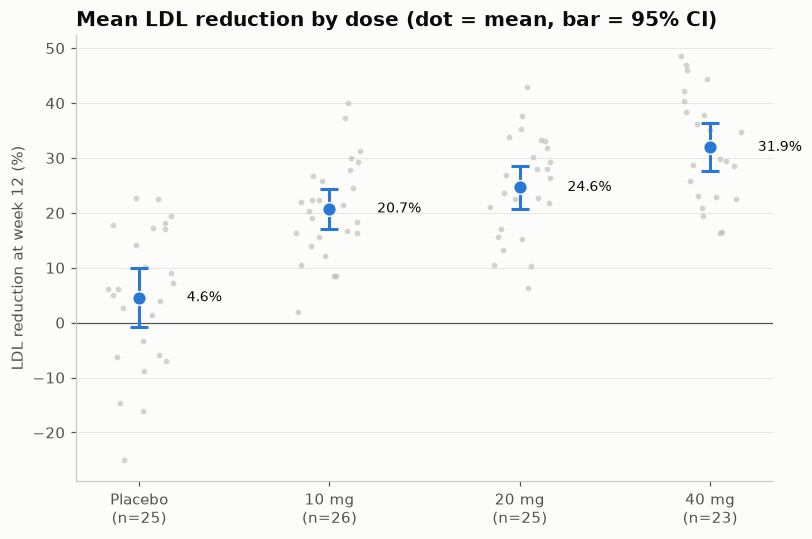

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for i, g in enumerate(groups):
    vals = df.loc[df.group == g, "ldl_reduction_pct"]
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(vals)), vals, s=14, color=GRAY, alpha=0.6, linewidth=0)
ax.errorbar(range(len(groups)), summary["mean"], yerr=summary["ci95"], fmt="o", color=PALETTE[0],
            markersize=9, capsize=6, elinewidth=2, capthick=2, markeredgecolor="#fcfcfb", zorder=3)
for i, (m, n) in enumerate(zip(summary["mean"], summary["count"])):
    ax.text(i + 0.25, m, f"{m:.1f}%", va="center", fontsize=9, color="#0b0b0b")
ax.set_xticks(range(len(groups)), [f"{g}\n(n={n})" for g, n in zip(groups, summary["count"])])
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.grid(axis="x", visible=False)
ax.set_ylabel("LDL reduction at week 12 (%)")
ax.set_title("Mean LDL reduction by dose (dot = mean, bar = 95% CI)")
fig.tight_layout()
plt.show()

## How to read it

Each blue dot is a group mean, and its bar is the 95% CI. Non-overlapping intervals between adjacent doses suggest a real dose-response, and the gray dots show the spread of individual patients.

---
Standalone script: [`error_bar_ci.py`](error_bar_ci.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)